In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Dataset Load

In [2]:
df = pd.read_csv("data/car_data.csv")

print(df.head())
print(df.shape)
print(df.columns.tolist())
print(df.info())

                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000      46000  Petrol   
4     Honda Amaze VX i-DTEC  2014         450000     141000  Diesel   

  seller_type transmission         owner  
0  Individual       Manual   First Owner  
1  Individual       Manual   First Owner  
2  Individual       Manual   First Owner  
3  Individual       Manual   First Owner  
4  Individual       Manual  Second Owner  
(4340, 8)
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-nu

### Data Cleaning

In [3]:
print("Missing Values:\n", df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()
for col in ["fuel", "transmission", "seller_type", "owner"]:
    if col in df.columns:
        df[col] = df[col].str.lower()

df["selling_price"] = pd.to_numeric(df["selling_price"], errors="coerce")
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["km_driven"] = pd.to_numeric(df["km_driven"], errors="coerce")
df = df.dropna(subset=["name", "year", "selling_price", "km_driven"])
df = df[(df["selling_price"] > 0) & (df["km_driven"] >= 0)].copy()

print("Cleaned Dataset:", df.shape)

Missing Values:
 name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64
Duplicate Rows: 763
Cleaned Dataset: (3577, 8)


C:\Users\Admin\AppData\Local\Temp\ipykernel_13604\188035869.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


### Feature Engineering

In [4]:
from datetime import datetime
df["car_age"] = datetime.now().year - df["year"]
df["brand"] = df["name"].str.split().str[0]
df = df[df["car_age"] >= 0].copy()
print(df[["name", "brand", "year", "car_age"]].head())

                       name    brand  year  car_age
0             Maruti 800 AC   Maruti  2007       19
1  Maruti Wagon R LXI Minor   Maruti  2007       19
2      Hyundai Verna 1.6 SX  Hyundai  2012       14
3    Datsun RediGO T Option   Datsun  2017        9
4     Honda Amaze VX i-DTEC    Honda  2014       12


### Exploratory Data Analysis (EDA)

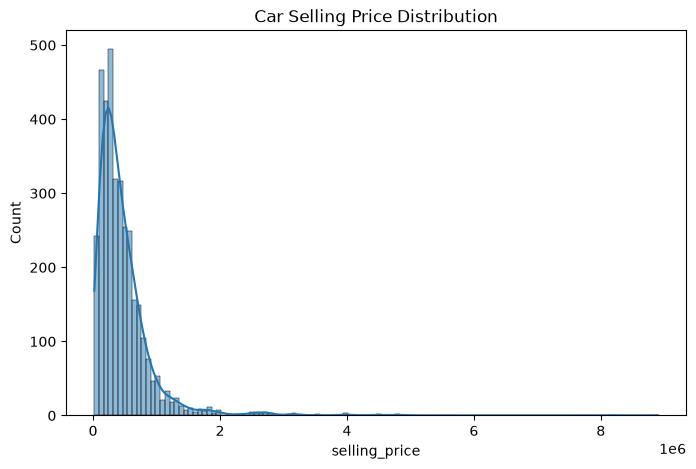

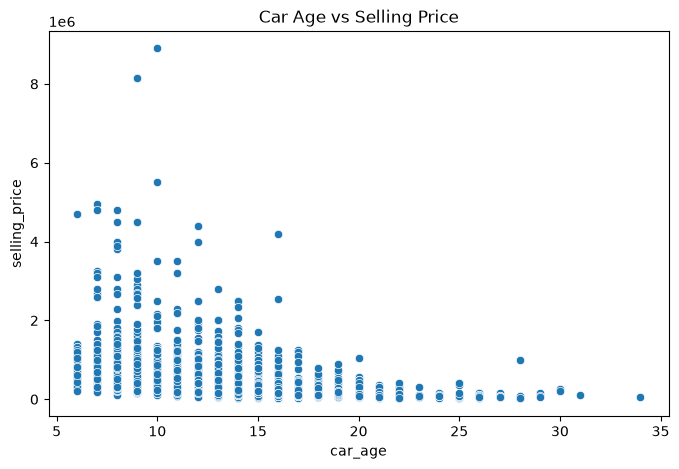

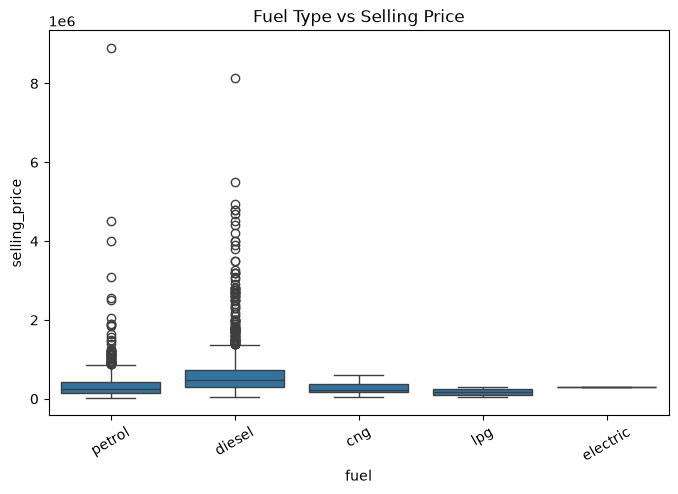

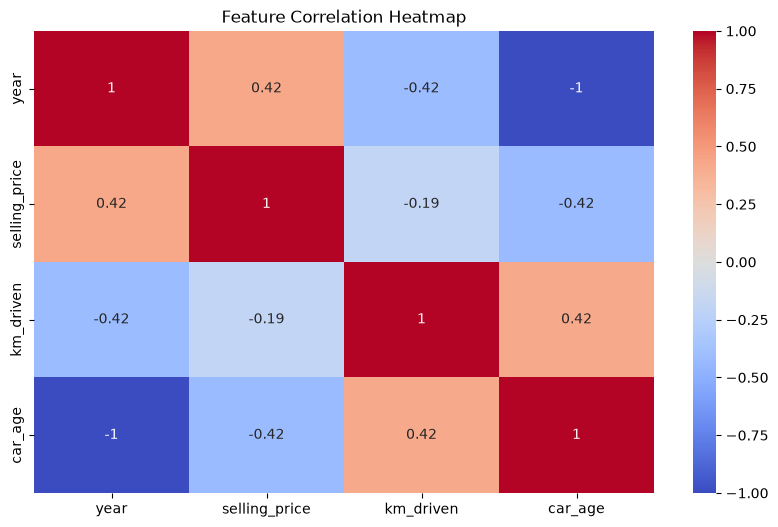

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="selling_price", kde=True)
plt.title("Car Selling Price Distribution")
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="car_age", y="selling_price")
plt.title("Car Age vs Selling Price")
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="fuel", y="selling_price")
plt.title("Fuel Type vs Selling Price")
plt.xticks(rotation=30)
plt.show()

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()

### Features

In [6]:
features = ["brand", "car_age", "km_driven", "fuel", "transmission"]
X = df[features].copy()
y = df["selling_price"].copy()
print("Features:", X.columns.tolist())
print("Target: selling_price")

Features: ['brand', 'car_age', 'km_driven', 'fuel', 'transmission']
Target: selling_price


### Train-Test Split

In [7]:
categorical_cols = ["brand", "fuel", "transmission"]
numerical_cols = ["car_age", "km_driven"]

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numerical_cols),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols)
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (2861, 5)
Testing Data: (716, 5)


### Regression Models Train

In [8]:
models = {"Linear Regression": LinearRegression(), "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)}
trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", model)])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    trained_models[name] = pipeline
    results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2 Score": r2})

results_df = pd.DataFrame(results)
print(results_df)

               Model            MAE           RMSE  R2 Score
0  Linear Regression  208837.231178  434710.715198  0.413369
1      Random Forest  160022.673066  368479.390552  0.578507


### Best Model

In [9]:
best_name = results_df.loc[results_df["MAE"].idxmin(), "Model"]
best_model = trained_models[best_name]
print("Best Model:", best_name)

Best Model: Random Forest


### Model Comparison Graph

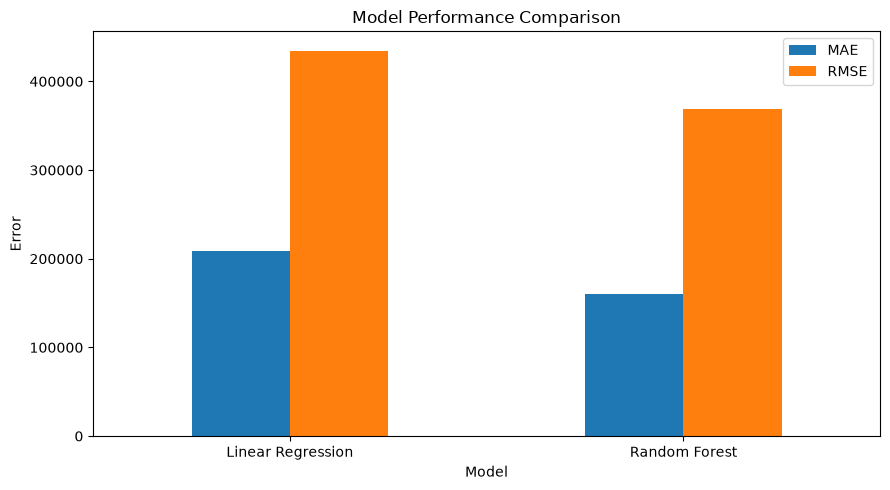

In [10]:
results_df.set_index("Model")[["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Feature Importance

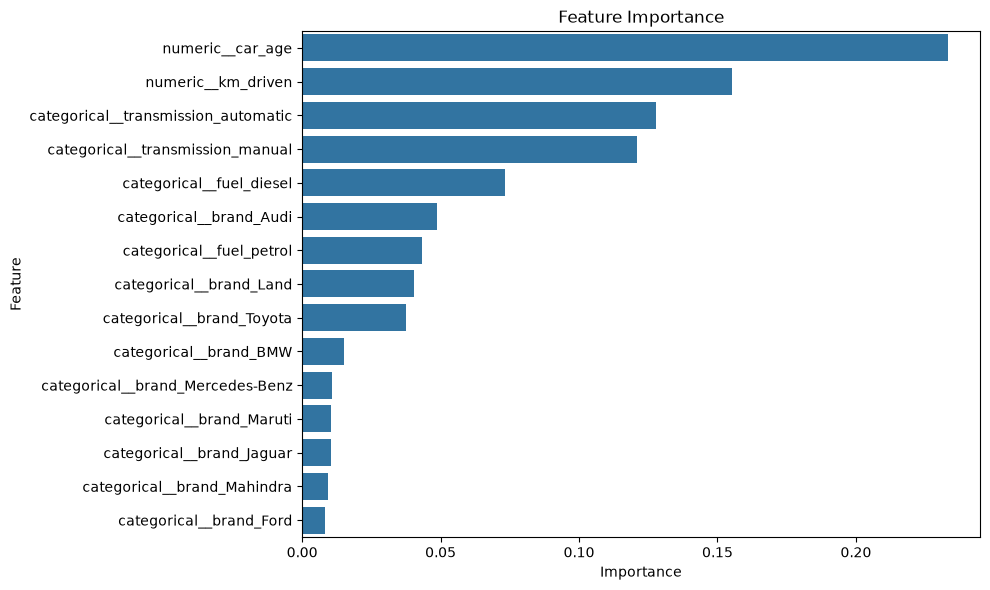

In [11]:
rf_model = trained_models["Random Forest"]
feature_names = (rf_model.named_steps["preprocessor"].get_feature_names_out())

importance = (rf_model.named_steps["model"].feature_importances_)
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importance}).sort_values("Importance", ascending=False).head(15)
plt.figure(figsize=(10, 6))

sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Feature Importance")
plt.tight_layout()
plt.show()

### Model Save

In [12]:
os.makedirs("models", exist_ok=True)
joblib.dump(best_model, "models/best_car_price_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [13]:
###